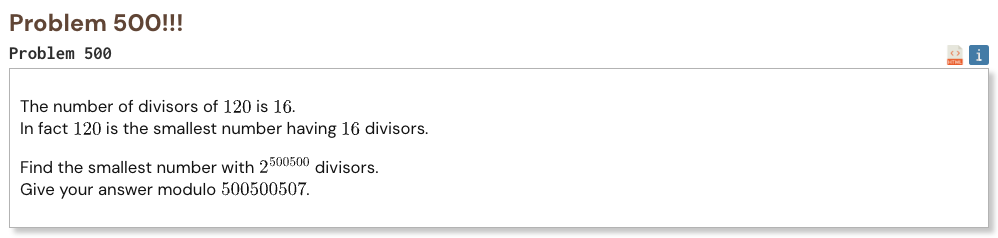

## Initial approach

- each selected prime starts with one factor that doubles the number of divisors
- increasing a prime exponent can double the divisor count again
- every upgrade has a multiplication cost such as a prime or a squared previous cost
- always choose the smallest available upgrade
- keep these upgrade costs in a priority queue
- after using one cost, replace it with its square for the next possible upgrade
- repeat this 500500 times and keep the product modulo 500500507

In [1]:
%%time

import heapq
import math

N = 500_500
MOD = 500_500_507
LIMIT = 8_000_000

sieve = bytearray(b"\x01") * (LIMIT + 1)
sieve[0:2] = b"\x00\x00"

for p in range(2, math.isqrt(LIMIT) + 1):
    if sieve[p]:
        start = p * p
        sieve[start:LIMIT + 1:p] = b"\x00" * (
            (LIMIT - start) // p + 1
        )

primes = [
    i
    for i in range(2, LIMIT + 1)
    if sieve[i]
][:N]

heap = primes[:]
heapq.heapify(heap)

result = 1

for _ in range(N):
    value = heapq.heappop(heap)

    result = (
        result * value
    ) % MOD

    heapq.heappush(
        heap,
        value * value
    )

print("Result:", result)

Result: 35407281
CPU times: user 381 ms, sys: 8.14 ms, total: 389 ms
Wall time: 390 ms
